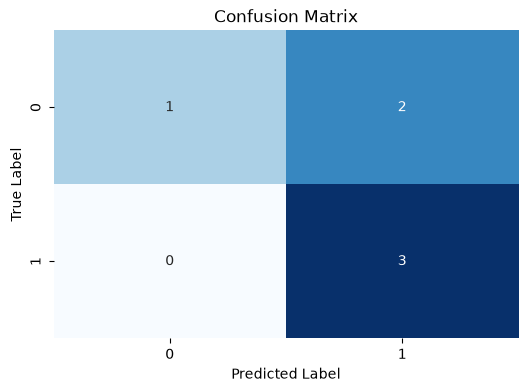

Total Errors Found: 2

Misclassified Samples:
    study_hours_per_week  attendance_rate  previous_gpa  \
23                   7.5             0.74           2.7   
7                    8.0             0.78           2.8   

    assignments_completed  midterm_score extracurricular  True_Label  \
23                    6.0             63             Yes           0   
7                     7.0             68             Yes           0   

    Predicted_Label  
23                1  
7                 1  


In [1]:
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

sys.path.append(os.path.abspath("../src"))
from preprocessing import build_preprocessor

# Load dataset
df = pd.read_csv("../data/student_performance.csv")
X = df.drop(columns=["student_id", "passed"])
y = df["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = [
    "study_hours_per_week",
    "attendance_rate",
    "previous_gpa",
    "assignments_completed",
    "midterm_score",
]
categorical_features = ["extracurricular"]
preprocessor = build_preprocessor(numeric_features, categorical_features)

# Train a model for error inspection
model = RandomForestClassifier(n_estimators=100, random_state=42)
pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])
pipe.fit(X_train, y_train)
preds = pipe.predict(X_test)

# Plot Confusion Matrix
cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Extract and inspect errors
test_results = X_test.copy()
test_results["True_Label"] = y_test.values
test_results["Predicted_Label"] = preds
errors = test_results[
    test_results["True_Label"] != test_results["Predicted_Label"]
]

print(f"Total Errors Found: {len(errors)}")
if len(errors) > 0:
  print("\nMisclassified Samples:")
  print(errors)
else:
  print(
      "\nNo errors found on this test split (due to clean linear separability"
      " in the small toy dataset)."
  )